# Proyecto: Análisis de Series de Tiempo
## Airline Baggage Complaints

**Equipo:**
- Huerta Rodríguez Sofía
- Zhang Tan Rubi

**Grupo:** 6AV1  
**Materia:** Análisis de Series de Tiempo


### Carga de datos

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import seasonal_decompose

df = pd.read_csv("/content/baggagecomplaints.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 252 entries, 0 to 251
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Airline    252 non-null    object
 1   Date       252 non-null    object
 2   Month      252 non-null    int64 
 3   Year       252 non-null    int64 
 4   Baggage    252 non-null    int64 
 5   Scheduled  252 non-null    int64 
 6   Cancelled  252 non-null    int64 
 7   Enplaned   252 non-null    int64 
dtypes: int64(6), object(2)
memory usage: 15.9+ KB


### Serie de Tiempo (2004–2010)

            Airline       Date
0    American Eagle 2004-01-01
168          United 2004-01-01
84         Hawaiian 2004-01-01
1    American Eagle 2004-02-01
169          United 2004-02-01


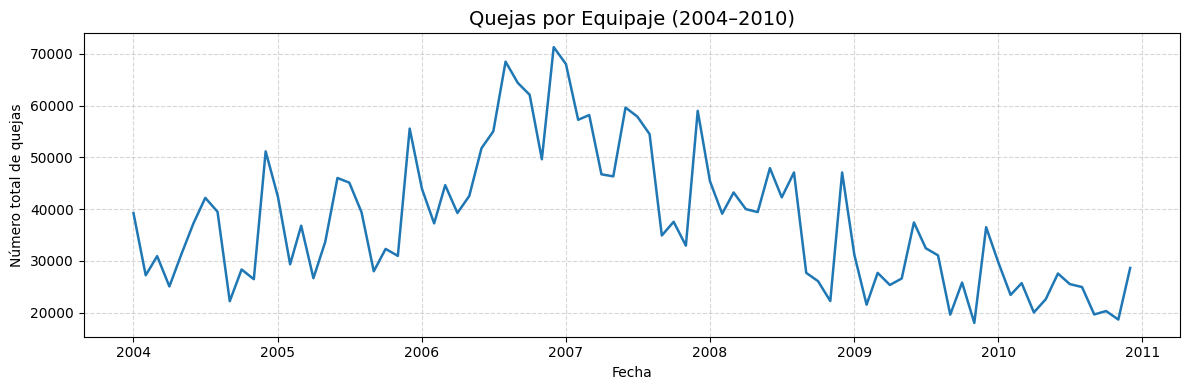

In [ ]:
df["Date"] = pd.to_datetime(dict(year=df["Year"], month=df["Month"], day=1))
df = df.sort_values("Date")

print(df[["Airline", "Date"]].head())

df_total = df.groupby("Date")["Baggage"].sum().reset_index()
df_total["Date"] = pd.to_datetime(df_total["Date"])
df_total = df_total.set_index("Date")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df_total.index, df_total["Baggage"], linewidth=1.8)
ax.set_title("Quejas por Equipaje (2004–2010)", fontsize=14)
ax.set_xlabel("Fecha")
ax.set_ylabel("Número total de quejas")
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Análisis Estadístico Descriptivo

In [ ]:
df.describe()

,Date,Month,Year,Baggage,Scheduled,Cancelled,Enplaned
count,252,252.000000,252.00000,252.000000,252.000000,252.000000,2.520000e+02
mean,2007-06-16 21:08:34.285714176,6.500000,2007.00000,12613.507937,28128.007937,703.761905,2.203871e+06
min,2004-01-01 00:00:00,1.000000,2004.00000,1033.000000,3553.000000,0.000000,4.234460e+05
25%,2005-09-23 12:00:00,3.750000,2005.00000,1910.500000,5565.750000,25.750000,6.865205e+05
50%,2007-06-16 00:00:00,6.500000,2007.00000,12224.000000,36696.000000,533.000000,1.391112e+06
75%,2009-03-08 18:00:00,9.250000,2009.00000,19359.250000,42162.500000,1078.500000,4.111049e+06
max,2010-12-01 00:00:00,12.000000,2010.00000,41787.000000,50837.000000,3712.000000,6.137271e+06
std,NaN,3.458922,2.00398,9993.307166,17092.087874,746.020368,1.788200e+06


###Análisis de Componentes

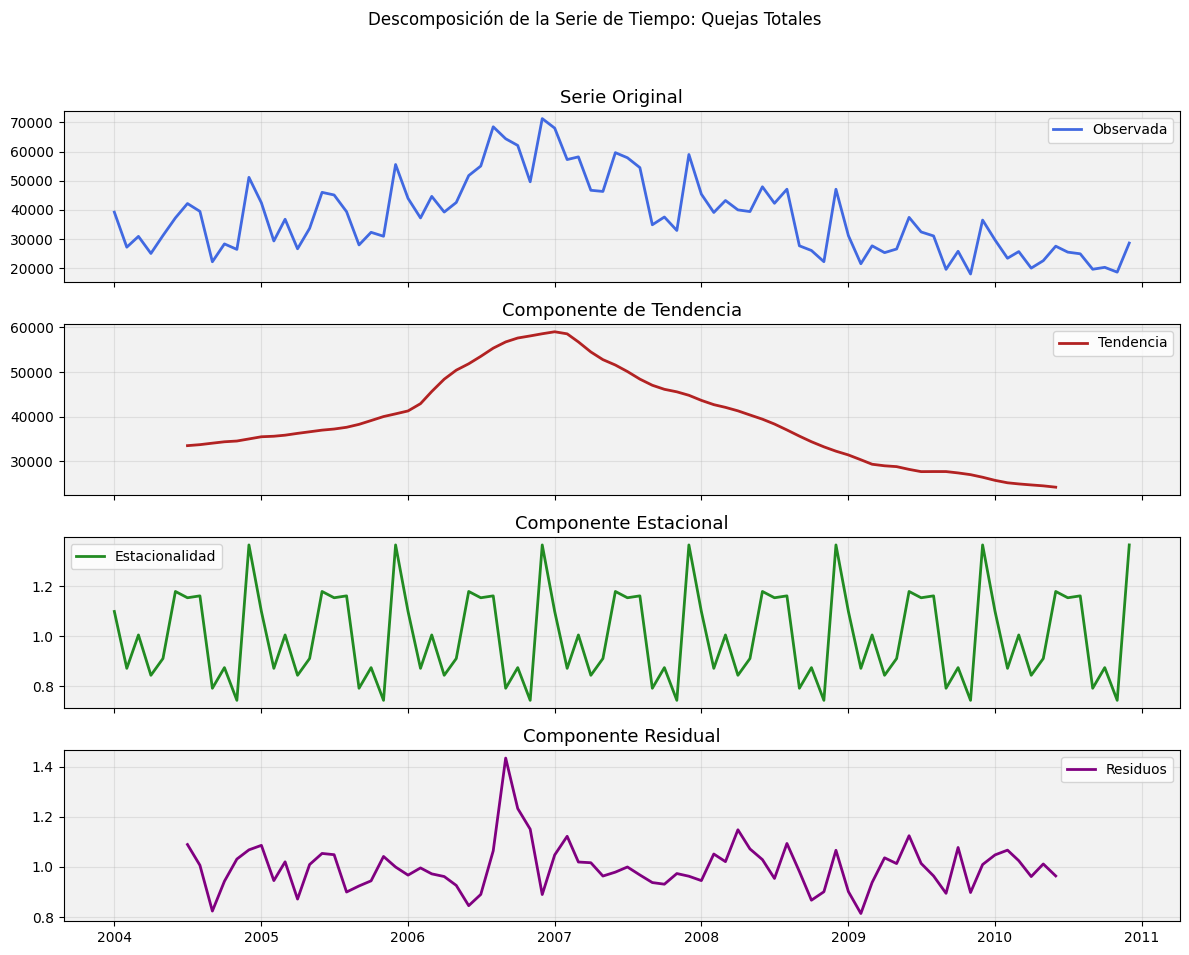

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Columna date
df["Date"] = pd.to_datetime(dict(year=df["Year"], month=df["Month"], day=1))
df = df.sort_values("Date")

# Agrupar por fecha para obtener la serie temporal global (Total de quejas)
df_total = df.groupby("Date")["Baggage"].sum().reset_index()
df_total.set_index("Date", inplace=True)

# Descomposición Estacional
descomposicion = seasonal_decompose(df_total["Baggage"], model='multiplicative', period=12) # El periodo es 12 porque los datos son mensuales y esperamos ciclos anuales

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

for ax in axes:
    ax.set_facecolor('#f2f2f2')
    ax.grid(True, alpha=0.3)

axes[0].plot(descomposicion.observed, color='royalblue', linewidth=2)
axes[0].set_title("Serie Original", fontsize=13 )
axes[0].legend(["Observada"])

axes[1].plot(descomposicion.trend, color='firebrick', linewidth=2)
axes[1].set_title("Componente de Tendencia", fontsize=13 )
axes[1].legend(["Tendencia"])

axes[2].plot(descomposicion.seasonal, color='forestgreen', linewidth=2)
axes[2].set_title("Componente Estacional", fontsize=13 )
axes[2].legend(["Estacionalidad"])

axes[3].plot(descomposicion.resid, color='purple', linewidth=2)
axes[3].set_title("Componente Residual", fontsize=13 )
axes[3].legend(["Residuos"])

plt.suptitle("Descomposición de la Serie de Tiempo: Quejas Totales")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Análisis Exploratorio de Autocorrelación



In [ ]:
import numpy as np
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

serie = df_total["Baggage"]

###Mapa de Calor de Correlación

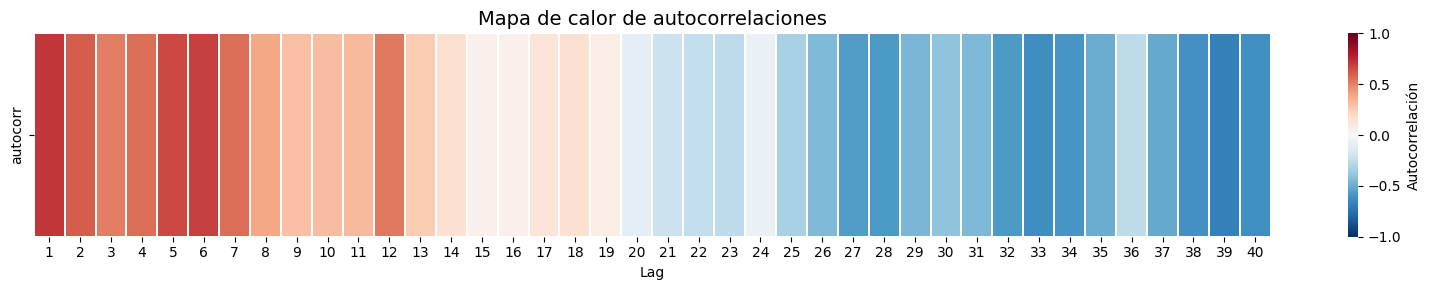

In [ ]:
#calculamos autocorrelaciones para lags del 1 al 40
max_lags = 40
autocorrs = [serie.autocorr(lag=k) for k in range(1, max_lags + 1)]
#construimos el df para el mapa de calor
df_heatmap = pd.DataFrame(
    [autocorrs],
    columns=[f"{k}" for k in range(1, max_lags + 1)],
    index=["autocorr"]
)

fig, ax = plt.subplots(figsize=(16, 3))
sns.heatmap(df_heatmap, ax=ax, cmap="RdBu_r", center=0,
    vmin=-1, vmax=1, annot=False, linewidths=0.3,
    cbar_kws={"label": "Autocorrelación"}
)
ax.set_title("Mapa de calor de autocorrelaciones", fontsize=14)
ax.set_xlabel("Lag")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

###Gráfica ACF

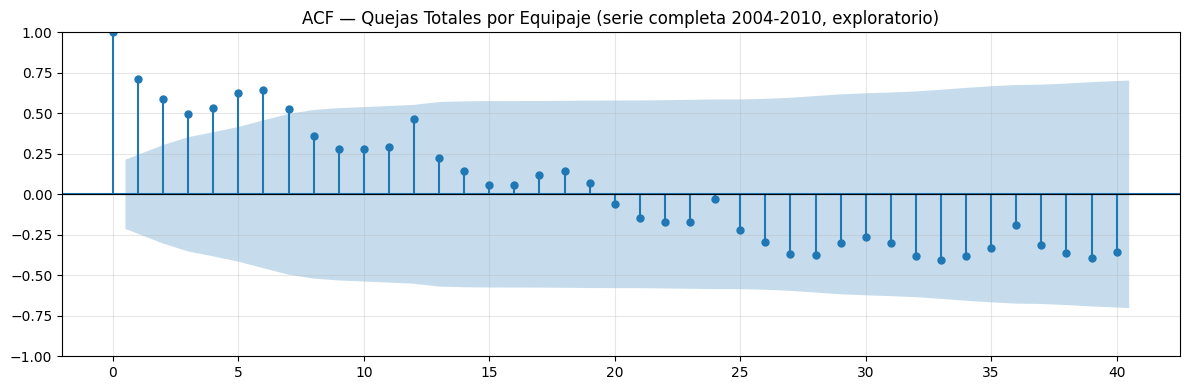

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.grid(True, alpha=0.3)
plot_acf(serie, lags=40, ax=ax,
    title="ACF — Quejas Totales por Equipaje (serie completa 2004-2010, exploratorio)")
ax.axhline(y=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()


###Gráfica PACF

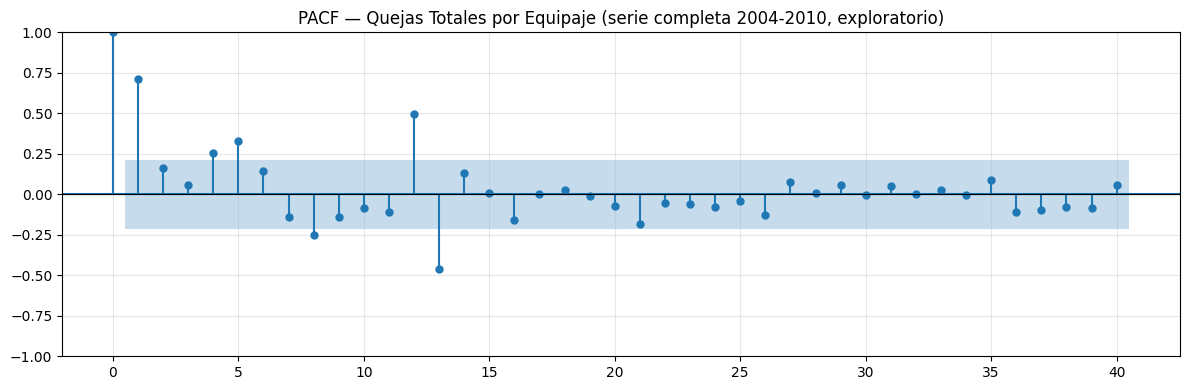

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.grid(True, alpha=0.3)
plot_pacf(serie, lags=40, ax=ax,
    title="PACF — Quejas Totales por Equipaje (serie completa 2004-2010, exploratorio)")
ax.axhline(y=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()


##Recorte de Serie Temporal (2007–2010)

Con base en el análisis exploratorio anterior, se recorta la serie desde 2007. Los años 2004–2006 tienen un comportamiento más irregular y heterogéneo, por lo que el segmento 2007–2010 es más homogéneo
y adecuado para el modelado.



In [ ]:
# Recortar la serie desde 2007
df_cortado = df[df["Year"] >= 2007].copy()

# Agregar por fecha para obtener total mensual de quejas
df_total = df_cortado.groupby("Date", as_index=False)["Baggage"].sum()
df_total["Date"] = pd.to_datetime(df_total["Date"])
df_total = df_total.sort_values("Date").set_index("Date")

# Serie de tiempo y número de observaciones
ts = df_total["Baggage"]
n_obs = len(ts)
print(f"Observaciones en la serie cortada (2007–2010): {n_obs}")

Observaciones en la serie cortada (2007–2010): 48


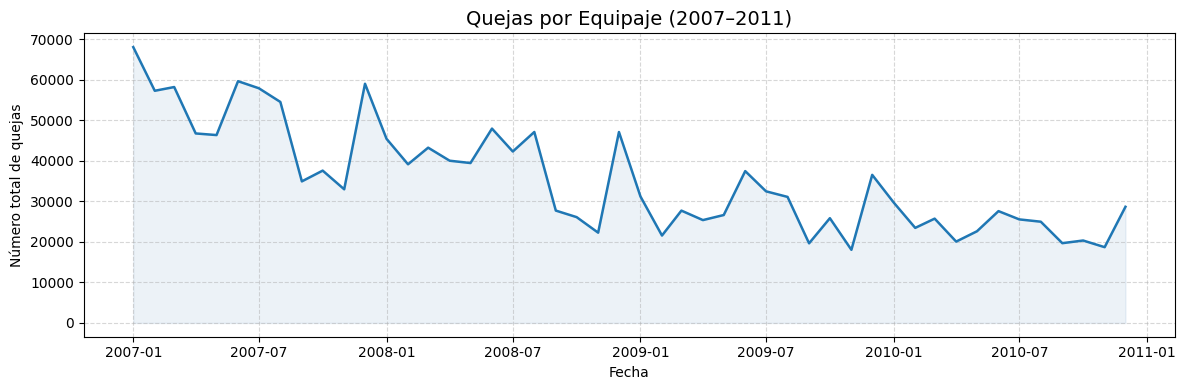

In [ ]:
# Gráfica de la serie recortada
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(ts.index, ts.values, linewidth=1.8)
ax.fill_between(ts.index, ts.values, alpha=0.1, color='steelblue')

ax.set_title('Quejas por Equipaje (2007–2011)', fontsize=14)
ax.set_xlabel('Fecha')
ax.set_ylabel('Número total de quejas')
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

##Estadísticas Móviles



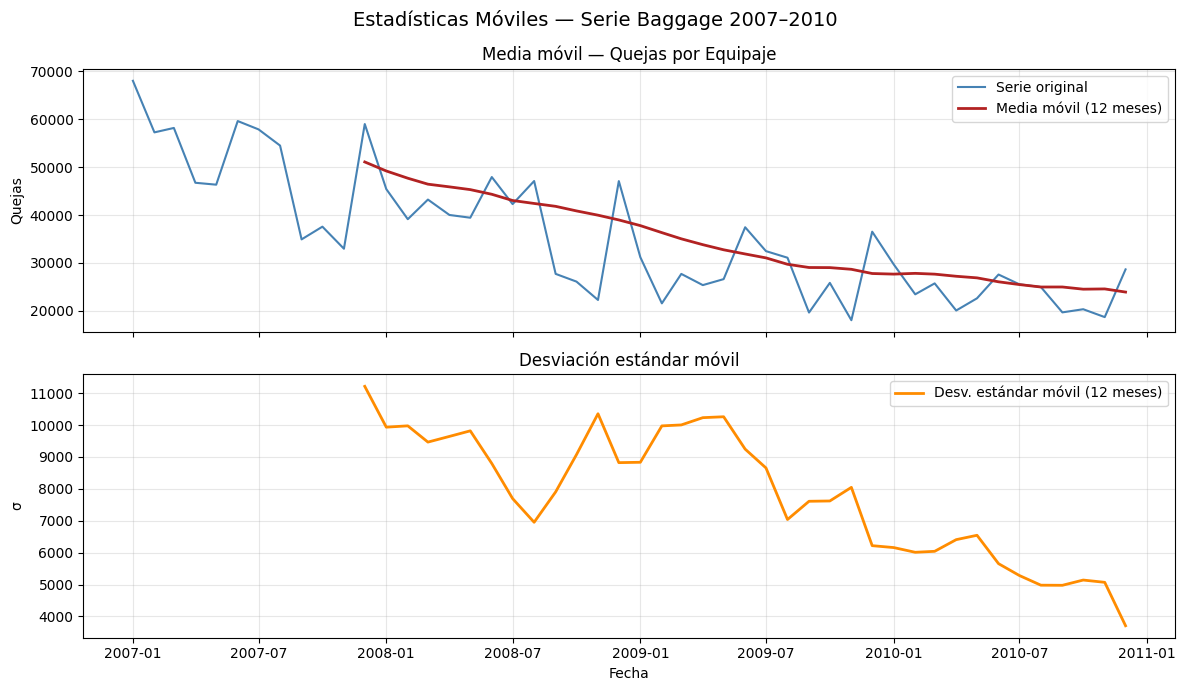

In [ ]:
window = 12  # ventana de 12 meses (un año)
rolling_mean = ts.rolling(window).mean()
rolling_std  = ts.rolling(window).std()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(ts, color='steelblue', linewidth=1.5, label='Serie original')
axes[0].plot(rolling_mean, color='firebrick', linewidth=2, label=f'Media móvil ({window} meses)')
axes[0].set_title('Media móvil — Quejas por Equipaje')
axes[0].set_ylabel('Quejas')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(rolling_std, color='darkorange', linewidth=2, label=f'Desv. estándar móvil ({window} meses)')
axes[1].set_title('Desviación estándar móvil')
axes[1].set_ylabel('σ')
axes[1].set_xlabel('Fecha')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Estadísticas Móviles — Serie Baggage 2007–2010', fontsize=14)
plt.tight_layout()
plt.show()


## Pruebas de Estacionariedad (2007–2010)




### Prueba ADF

Número máximo de rezagos (regla de Schwert): 9

--- ADF Con constante ('c') ---
  Estadístico ADF    : -2.0305
  p-valor            : 0.2733
  Rezagos usados     : 5
  Valores críticos   : 1%: -3.597  5%: -2.933  10%: -2.605
  Conclusión (5%)    : No se rechaza H0: posible raíz unitaria

--- ADF Constante y tendencia ('ct') ---
  Estadístico ADF    : -5.2989
  p-valor            : 0.0001
  Rezagos usados     : 2
  Valores críticos   : 1%: -4.175  5%: -3.513  10%: -3.187
  Conclusión (5%)    : Se rechaza H0: serie estacionaria


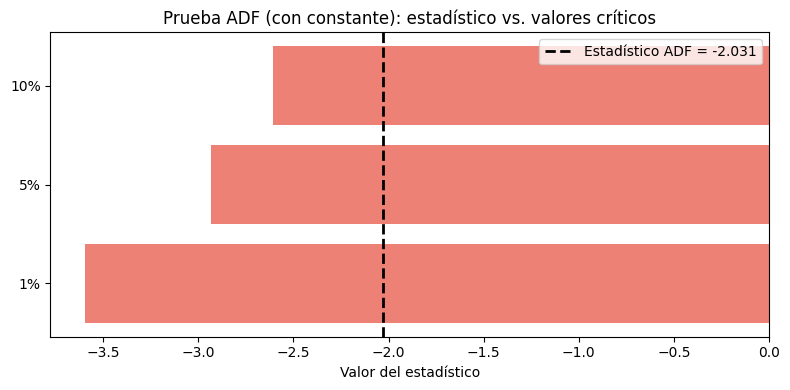

In [ ]:
from statsmodels.tsa.stattools import adfuller

p_max = int(12 * (n_obs / 100) ** 0.25)
print(f"Número máximo de rezagos (regla de Schwert): {p_max}")

adf_c  = adfuller(ts, maxlag=p_max, autolag='aic', regression='c')
adf_ct = adfuller(ts, maxlag=p_max, autolag='aic', regression='ct')

for label, res in [("Con constante ('c')", adf_c), ("Constante y tendencia ('ct')", adf_ct)]:
    print(f"\n--- ADF {label} ---")
    print(f"  Estadístico ADF    : {res[0]:.4f}")
    print(f"  p-valor            : {res[1]:.4f}")
    print(f"  Rezagos usados     : {res[2]}")
    print(f"  Valores críticos   : " + "  ".join([f"{k}: {v:.3f}" for k, v in res[4].items()]))
    concl = "Se rechaza H0: serie estacionaria" if res[1] < 0.05 else "No se rechaza H0: posible raíz unitaria"
    print(f"  Conclusión (5%)    : {concl}")

fig, ax = plt.subplots(figsize=(8, 4))
criticos = adf_c[4]
niveles  = list(criticos.keys())
valores  = list(criticos.values())
colores_bar = ['#2ecc71' if adf_c[0] < v else '#e74c3c' for v in valores]
ax.barh(niveles, valores, color=colores_bar, alpha=0.7)
ax.axvline(adf_c[0], color='black', linewidth=2, linestyle='--',
           label=f'Estadístico ADF = {adf_c[0]:.3f}')
ax.set_xlabel('Valor del estadístico')
ax.set_title('Prueba ADF (con constante): estadístico vs. valores críticos')
ax.legend()
plt.tight_layout()
plt.show()


### Prueba KPSS

In [ ]:
from statsmodels.tsa.stattools import kpss

print("Prueba KPSS — Serie recortada (2007–2010)")

def run_kpss(serie, label, regression='c'):
    stat, p_val, n_lags, crit = kpss(serie.dropna(), regression=regression, nlags='auto')
    concl = "No se rechaza H0: serie estacionaria" if p_val > 0.05 else "Se rechaza H0: serie NO estacionaria"
    print(f"\n--- KPSS {label} (regression='{regression}') ---")
    print(f"  Estadístico KPSS : {stat:.4f}")
    print(f"  p-valor          : {p_val:.4f}")
    print(f"  Rezagos usados   : {n_lags}")
    crit_str = "  ".join([f"{k}: {v:.3f}" for k, v in crit.items()])
    print(f"  Valores críticos : {crit_str}")
    print(f"  Conclusión (5%)  : {concl}")
    return stat, p_val

# Serie original
stat_orig, p_orig = run_kpss(ts, "Serie recortada (2007–2010)", regression='c')


Prueba KPSS — Serie recortada (2007–2010)

--- KPSS Serie recortada (2007–2010) (regression='c') ---
  Estadístico KPSS : 1.0014
  p-valor          : 0.0100
  Rezagos usados   : 4
  Valores críticos : 10%: 0.347  5%: 0.463  2.5%: 0.574  1%: 0.739
  Conclusión (5%)  : Se rechaza H0: serie NO estacionaria


/tmp/ipykernel_12167/2392684864.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stat, p_val, n_lags, crit = kpss(serie.dropna(), regression=regression, nlags='auto')


## Prueba de Autocorrelación — Ljung-Box


In [ ]:
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox

lags_lb   = sorted(set([5, 10, 15, 20, int(np.log(n_obs))]))
lb_result = acorr_ljungbox(ts, lags=lags_lb, return_df=True)

print("Prueba Ljung-Box — Serie recortada (2007–2010)")
print(f"{'Rezago h':>10} {'Q_LB':>12} {'p-valor':>12} {'Conclusión':>22}")
print("-" * 58)
for h, row in lb_result.iterrows():
    q = float(row['lb_stat'])
    p = float(row['lb_pvalue'])
    c = 'Rechaza H0 ✗' if p < 0.05 else 'No rechaza H0 ✓'
    print(f"{int(h):>10} {q:>12.4f} {p:>12.6f} {c:>22}")


Prueba Ljung-Box — Serie recortada (2007–2010)
  Rezago h         Q_LB      p-valor             Conclusión
----------------------------------------------------------
         3      47.9498     0.000000           Rechaza H0 ✗
         5      77.2285     0.000000           Rechaza H0 ✗
        10     110.9338     0.000000           Rechaza H0 ✗
        15     128.5420     0.000000           Rechaza H0 ✗
        20     132.5910     0.000000           Rechaza H0 ✗


## Transformaciones para Estacionariedad

1. **Logaritmo natural** → estabiliza la varianza (heteroscedasticidad)
2. **Diferenciación de orden 1** → elimina la tendencia (d = 1)



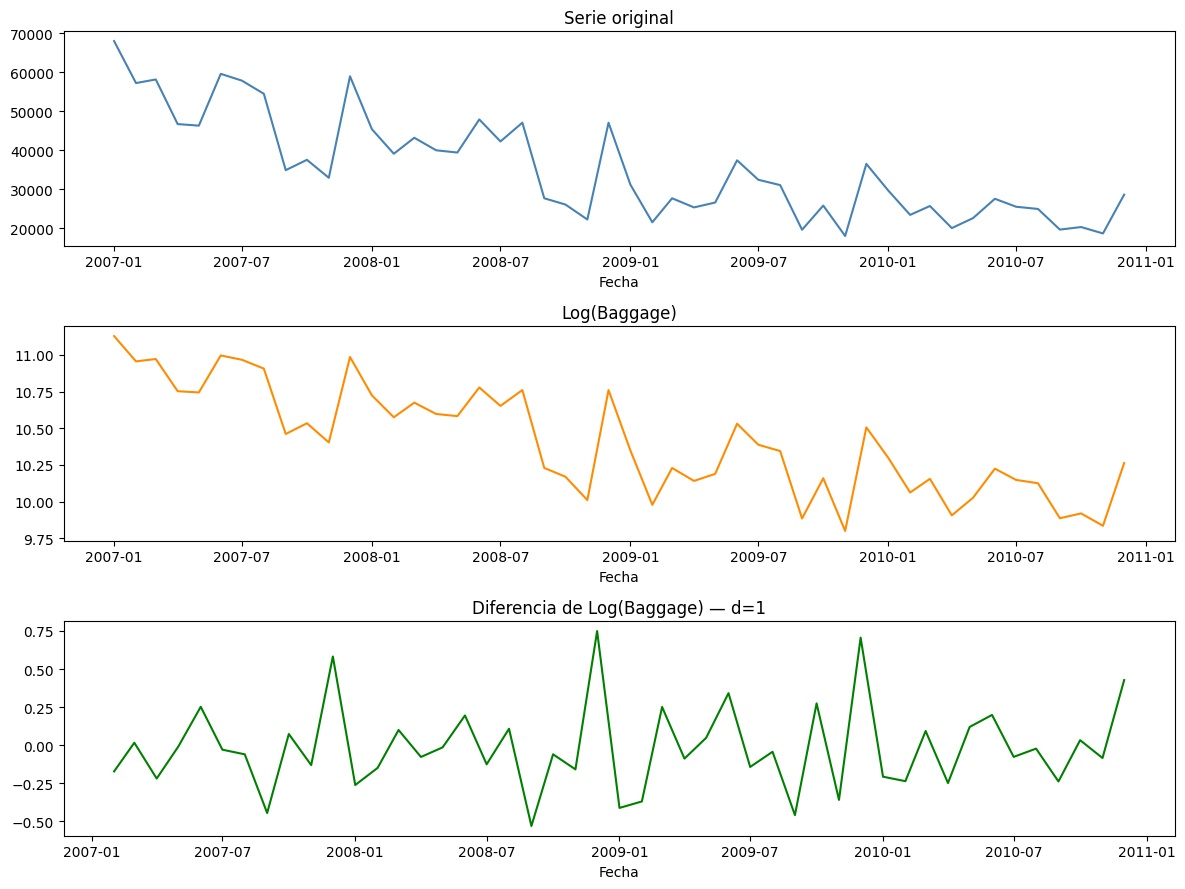

In [ ]:
# Tranformación: log + diferenciación
ts_log  = np.log(ts)                  # estabiliza varianza
ts_diff = ts_log.diff().dropna()      # elimina tendencia (d=1)

fig, axes = plt.subplots(3, 1, figsize=(12, 9))
axes[0].plot(ts,      color='steelblue');  axes[0].set_title('Serie original')
axes[1].plot(ts_log,  color='darkorange'); axes[1].set_title('Log(Baggage)')
axes[2].plot(ts_diff, color='green');      axes[2].set_title('Diferencia de Log(Baggage) — d=1')
for ax in axes:
    ax.set_xlabel('Fecha')
plt.tight_layout()
plt.show()

## Verificación de Estacionariedad Post-Transformación

Se re-aplican ADF y KPSS sobre la serie transformada ∇log(Baggage) para confirmar que las transformaciones fueron suficientes.


In [ ]:
# ADF sobre la serie transformada
n_diff = len(ts_diff)
p_max_diff = int(12 * (n_diff / 100) ** 0.25)

adf_diff_c  = adfuller(ts_diff, maxlag=p_max_diff, autolag='aic', regression='c')
adf_diff_ct = adfuller(ts_diff, maxlag=p_max_diff, autolag='aic', regression='ct')

print("Prueba ADF sobre ∇log(Baggage) — serie transformada")
print("=" * 60)
for label, res in [("Con constante ('c')", adf_diff_c),
                    ("Constante y tendencia ('ct')", adf_diff_ct)]:
    print(f"\n--- ADF {label} ---")
    print(f"  Estadístico ADF    : {res[0]:.4f}")
    print(f"  p-valor            : {res[1]:.4f}")
    print(f"  Rezagos usados     : {res[2]}")
    vc = '  '.join([f"{k}: {v:.3f}" for k, v in res[4].items()])
    print(f"  Valores críticos   : {vc}")
    concl = "Se rechaza H0: serie estacionaria" if res[1] < 0.05 \
             else "No se rechaza H0: posible raíz unitaria"
    print(f"  Conclusión (5%)    : {concl}")


Prueba ADF sobre ∇log(Baggage) — serie transformada

--- ADF Con constante ('c') ---
  Estadístico ADF    : -6.7424
  p-valor            : 0.0000
  Rezagos usados     : 4
  Valores críticos   : 1%: -3.597  5%: -2.933  10%: -2.605
  Conclusión (5%)    : Se rechaza H0: serie estacionaria

--- ADF Constante y tendencia ('ct') ---
  Estadístico ADF    : -6.7586
  p-valor            : 0.0000
  Rezagos usados     : 4
  Valores críticos   : 1%: -4.192  5%: -3.521  10%: -3.191
  Conclusión (5%)    : Se rechaza H0: serie estacionaria


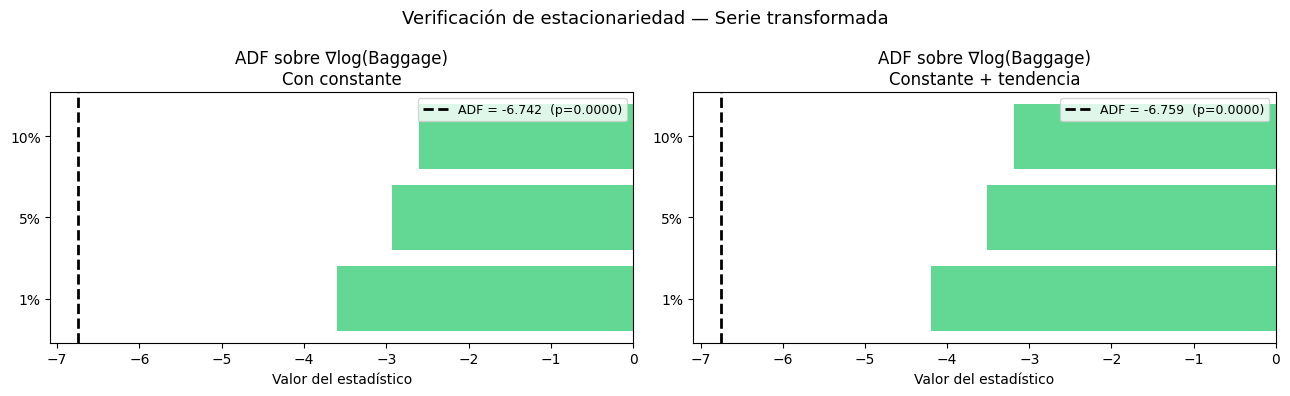

In [ ]:
# Visualización comparativa: estadístico ADF vs valores críticos (serie transformada)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, (label, res) in zip(axes, [
        ("Con constante", adf_diff_c),
        ("Constante + tendencia", adf_diff_ct)]):
    criticos = res[4]
    niveles  = list(criticos.keys())
    valores  = list(criticos.values())
    colores_bar = ['#2ecc71' if res[0] < v else '#e74c3c' for v in valores]
    ax.barh(niveles, valores, color=colores_bar, alpha=0.75)
    ax.axvline(res[0], color='black', linewidth=2, linestyle='--',
               label=f'ADF = {res[0]:.3f}  (p={res[1]:.4f})')
    ax.set_xlabel('Valor del estadístico')
    ax.set_title(f'ADF sobre ∇log(Baggage)\n{label}')
    ax.legend(fontsize=9)

plt.suptitle('Verificación de estacionariedad — Serie transformada', fontsize=13)
plt.tight_layout()
plt.show()


### Prueba KPSS


Prueba KPSS — Serie transformada ∇log(Baggage)

--- KPSS Serie transformada ∇log(Baggage) (regression='c') ---
  Estadístico KPSS : 0.2129
  p-valor          : 0.1000
  Rezagos usados   : 6
  Valores críticos : 10%: 0.347  5%: 0.463  2.5%: 0.574  1%: 0.739
  Conclusión (5%)  : No se rechaza H0: serie estacionaria


/tmp/ipykernel_12167/2392684864.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  stat, p_val, n_lags, crit = kpss(serie.dropna(), regression=regression, nlags='auto')
/tmp/ipykernel_12167/4144870173.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  ("Serie original", stat_orig, p_orig, kpss(ts.dropna(), regression='c', nlags='auto')[3]),
/tmp/ipykernel_12167/4144870173.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  ("∇log(Baggage)",  stat_diff, p_diff, kpss(ts_diff.dropna(), regression='c', nlags='auto')[3]),


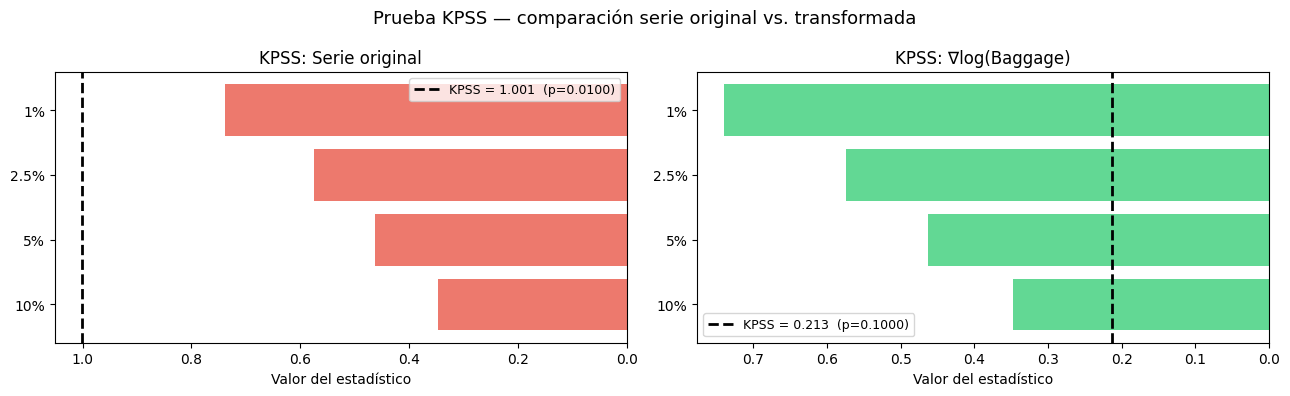

In [ ]:
print("Prueba KPSS — Serie transformada ∇log(Baggage)")
print("=" * 60)

stat_diff, p_diff = run_kpss(ts_diff, "Serie transformada ∇log(Baggage)", regression='c')

# Visualización comparativa KPSS original vs transformada
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, (label, stat, p_val, crit_vals) in zip(axes, [
    ("Serie original", stat_orig, p_orig, kpss(ts.dropna(), regression='c', nlags='auto')[3]),
    ("∇log(Baggage)",  stat_diff, p_diff, kpss(ts_diff.dropna(), regression='c', nlags='auto')[3]),
]):
    niveles = list(crit_vals.keys())
    valores = list(crit_vals.values())
    colores_bar = ['#e74c3c' if stat > v else '#2ecc71' for v in valores]
    ax.barh(niveles, valores, color=colores_bar, alpha=0.75)
    ax.axvline(stat, color='black', linewidth=2, linestyle='--',
               label=f'KPSS = {stat:.3f}  (p={p_val:.4f})')
    ax.set_xlabel('Valor del estadístico')
    ax.set_title(f'KPSS: {label}')
    ax.legend(fontsize=9)
    ax.invert_xaxis()

plt.suptitle('Prueba KPSS — comparación serie original vs. transformada', fontsize=13)
plt.tight_layout()
plt.show()


## Análisis de Correlación de la Serie Transformada

Se analiza su estructura de autocorrelación para identificar los órdenes del modelo.


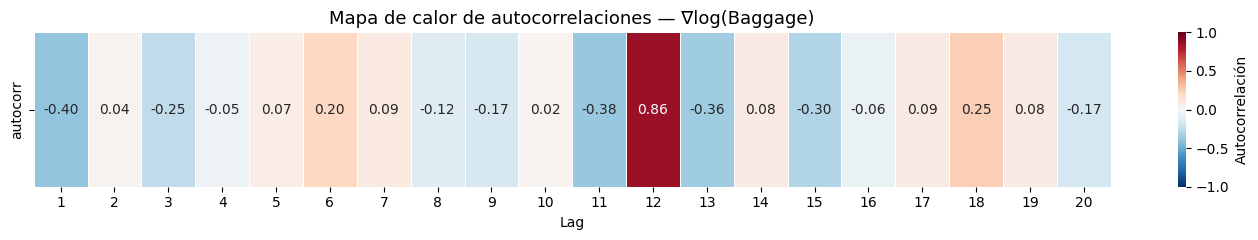

In [ ]:
# Mapa de calor de autocorrelaciones
max_lags = 20  # 20 lags es suficiente porque la serie es más corta
autocorrs_diff = [ts_diff.autocorr(lag=k) for k in range(1, max_lags + 1)]

df_heatmap_diff = pd.DataFrame(
    [autocorrs_diff],
    columns=[f"{k}" for k in range(1, max_lags + 1)],
    index=["autocorr"]
)

fig, ax = plt.subplots(figsize=(14, 2.5))
sns.heatmap(df_heatmap_diff, ax=ax, cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, annot=True, fmt='.2f', linewidths=0.4,
            cbar_kws={"label": "Autocorrelación"})
ax.set_title("Mapa de calor de autocorrelaciones — ∇log(Baggage)", fontsize=13)
ax.set_xlabel("Lag")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

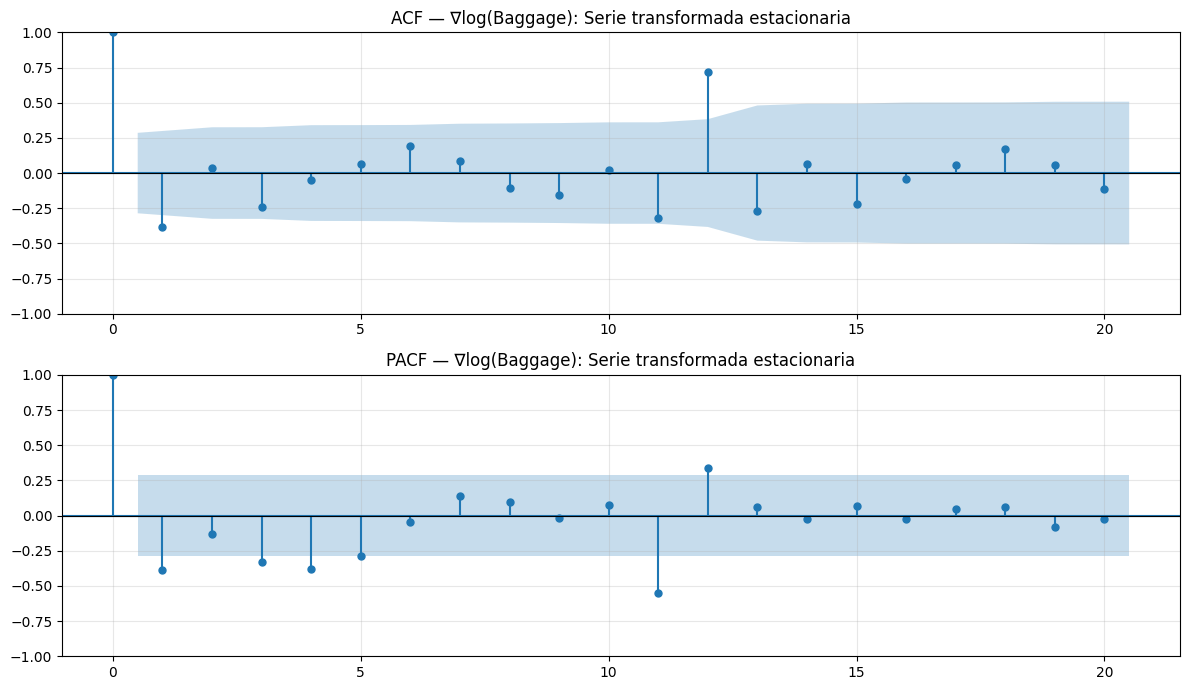

In [ ]:
# ACF y PACF de la serie transformada
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

for ax in axes:
    ax.grid(True, alpha=0.3)

plot_acf(ts_diff, lags=20, ax=axes[0],
         title="ACF — ∇log(Baggage): Serie transformada estacionaria")
axes[0].axhline(y=0, color='black', linewidth=0.8)

plot_pacf(ts_diff, lags=20, ax=axes[1],
          title="PACF — ∇log(Baggage): Serie transformada estacionaria")
axes[1].axhline(y=0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()

## Propuesta de Órdenes para Modelado

A partir de la ACF y PACF de ∇log(Baggage):

- **Orden de integración**: d = 1 ( por ADF y KPSS)
- **ACF**: corte abrupto después del lag 1 → sugiere **MA(1)**, q = 1
- **PACF**: decaimiento exponencial → compatible con MA puro o ARMA
- **Candidatos**: AR(1), MA(1), ARMA(1,1)


## Ajuste de Modelos ARIMA


In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings
warnings.filterwarnings('ignore')

# Serie de trabajo: log + diferenciación (d=1)
# El modelo se estima sobre ts_log; la diferenciación la maneja el parámetro d
ts_work = ts_log  # ARIMA(p,1,q) diferencia internamente

modelos = {
    "AR(1)    → ARIMA(1,1,0)": (1, 1, 0),
    "MA(1)    → ARIMA(0,1,1)": (0, 1, 1),
    "ARMA(1,1)→ ARIMA(1,1,1)": (1, 1, 1),
}

resultados = {}

for nombre, orden in modelos.items():
    print(f"\nMODELO: {nombre}\n")


    modelo = ARIMA(ts_work, order=orden)
    fit    = modelo.fit()
    resultados[nombre] = fit

    print(fit.summary().tables[1])
    print(f"\n  AIC : {fit.aic:.4f}")
    print(f"  BIC : {fit.bic:.4f}")


MODELO: AR(1)    → ARIMA(1,1,0)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3909      0.167     -2.340      0.019      -0.718      -0.064
sigma2         0.0661      0.012      5.319      0.000       0.042       0.090

  AIC : 9.8735
  BIC : 13.5738

MODELO: MA(1)    → ARIMA(0,1,1)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.6974      0.080     -8.720      0.000      -0.854      -0.541
sigma2         0.0566      0.013      4.266      0.000       0.031       0.083

  AIC : 3.1133
  BIC : 6.8136

MODELO: ARMA(1,1)→ ARIMA(1,1,1)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1162      0.352      0.330  

### Diagnóstico de Residuos — Ljung-Box


  Prueba de LJUNG-BOX sobre residuos

--- AR(1)    → ARIMA(1,1,0) ---
  Rezago h         Q_LB      p-valor           Conclusión
-------------------------------------------------------
         5       0.0936     0.999862      No rechaza H0 ✓
        10       0.2688     1.000000      No rechaza H0 ✓
        15       0.4522     1.000000      No rechaza H0 ✓
        20       0.7176     1.000000      No rechaza H0 ✓

--- MA(1)    → ARIMA(0,1,1) ---
  Rezago h         Q_LB      p-valor           Conclusión
-------------------------------------------------------
         5       0.0692     0.999935      No rechaza H0 ✓
        10       0.2762     1.000000      No rechaza H0 ✓
        15       0.3827     1.000000      No rechaza H0 ✓
        20       0.5896     1.000000      No rechaza H0 ✓

--- ARMA(1,1)→ ARIMA(1,1,1) ---
  Rezago h         Q_LB      p-valor           Conclusión
-------------------------------------------------------
         5       0.0654     0.999943      No rechaza H0 ✓


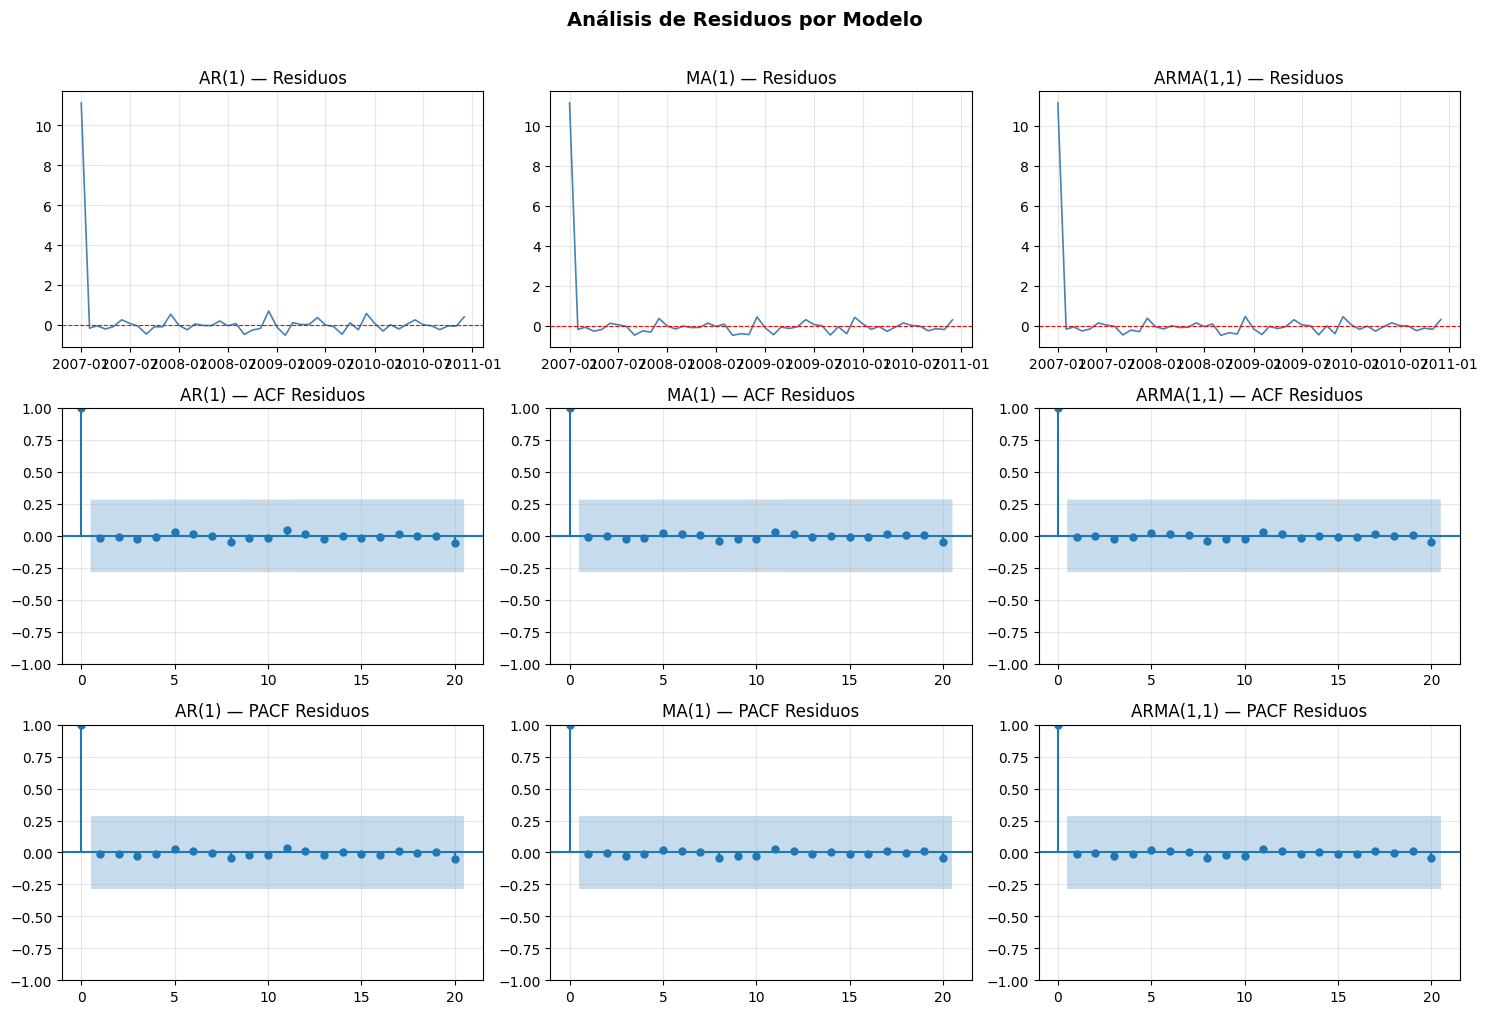


Comparación de criterios:

Modelo                      AIC        BIC
----------------------------------------
AR(1)                    9.8735    13.5738
MA(1)                    3.1133     6.8136
ARMA(1,1)                4.7032    10.2536

  → El modelo con menor AIC/BIC: MA(1) es el más adecuado.


In [ ]:
print("  Prueba de LJUNG-BOX sobre residuos")

lags_res = [5, 10, 15, 20]

for nombre, fit in resultados.items():
    residuos = fit.resid.dropna()
    lb = acorr_ljungbox(residuos, lags=lags_res, return_df=True)

    print(f"\n--- {nombre} ---")
    print(f"{'Rezago h':>10} {'Q_LB':>12} {'p-valor':>12} {'Conclusión':>20}")
    print("-" * 55)
    for _, row in lb.iterrows():
        q = float(row['lb_stat'])
        p = float(row['lb_pvalue'])
        c = 'Rechaza H0 ✗' if p < 0.05 else 'No rechaza H0 ✓'
        print(f"{int(row.name):>10} {q:>12.4f} {p:>12.6f} {c:>20}")

# Gráfica de residuos
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for col, (nombre, fit) in enumerate(resultados.items()):
    residuos = fit.resid.dropna()
    nombre_corto = nombre.split("→")[0].strip()

    # Residuos en el tiempo
    axes[0, col].plot(residuos, color='steelblue', linewidth=1.2)
    axes[0, col].axhline(0, color='red', linestyle='--', linewidth=0.8)
    axes[0, col].set_title(f'{nombre_corto} — Residuos')
    axes[0, col].grid(True, alpha=0.3)

    # ACF de residuos
    plot_acf(residuos, lags=20, ax=axes[1, col], title=f'{nombre_corto} — ACF Residuos')
    axes[1, col].grid(True, alpha=0.3)

    # PACF de residuos
    plot_pacf(residuos, lags=20, ax=axes[2, col], title=f'{nombre_corto} — PACF Residuos',
              method='ywm')
    axes[2, col].grid(True, alpha=0.3)

plt.suptitle('Análisis de Residuos por Modelo', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


#Comparación final
print("\nComparación de criterios:\n")
print(f"{'Modelo':<20} {'AIC':>10} {'BIC':>10}")
print("-" * 40)
for nombre, fit in resultados.items():
    nombre_corto = nombre.split("→")[0].strip()
    print(f"{nombre_corto:<20} {fit.aic:>10.4f} {fit.bic:>10.4f}")
print(f"\n  → El modelo con menor AIC/BIC: MA(1) es el más adecuado.")

### Análisis del Componente Aleatorio — Prueba ARCH-LM

Una vez seleccionado el modelo MA(1), se verifica si los residuos presentan **heteroscedasticidad condicional** (efectos ARCH):
- **H₀**: varianza constante (homocedasticidad)
- **H₁**: existe efecto ARCH de orden q


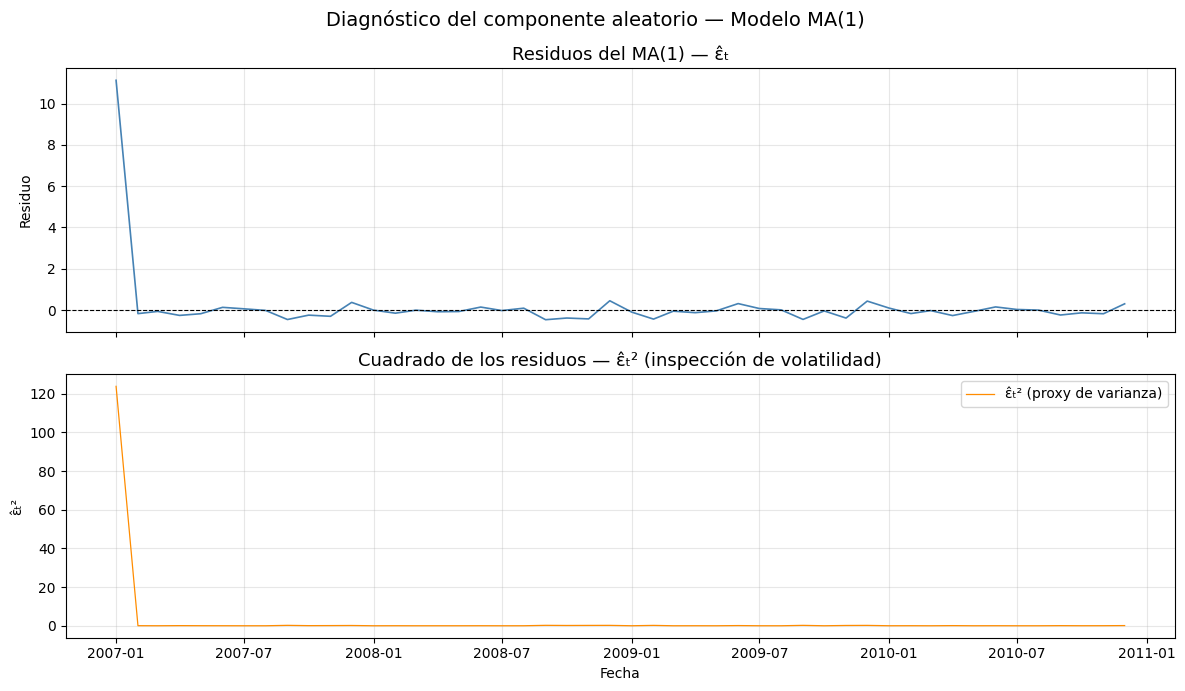

In [ ]:
from statsmodels.stats.diagnostic import het_arch
from statsmodels.tsa.arima.model import ARIMA
import warnings
warnings.filterwarnings('ignore')

# Re-estimar modelo MA(1) seleccionado
modelo_ma1 = ARIMA(ts_log, order=(0, 1, 1))
fit_ma1 = modelo_ma1.fit()
residuos_ma1 = fit_ma1.resid.dropna()

# Inspección visual: residuos y residuos al cuadrado
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(residuos_ma1, color='steelblue', linewidth=1.2)
axes[0].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[0].set_title('Residuos del MA(1) — ε̂ₜ', fontsize=13)
axes[0].set_ylabel('Residuo')
axes[0].grid(True, alpha=0.3)

axes[1].plot(residuos_ma1**2, color='darkorange', linewidth=0.9, label='ε̂ₜ² (proxy de varianza)')
axes[1].set_title('Cuadrado de los residuos — ε̂ₜ² (inspección de volatilidad)', fontsize=13)
axes[1].set_ylabel('ε̂ₜ²')
axes[1].set_xlabel('Fecha')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Diagnóstico del componente aleatorio — Modelo MA(1)', fontsize=14)
plt.tight_layout()
plt.show()


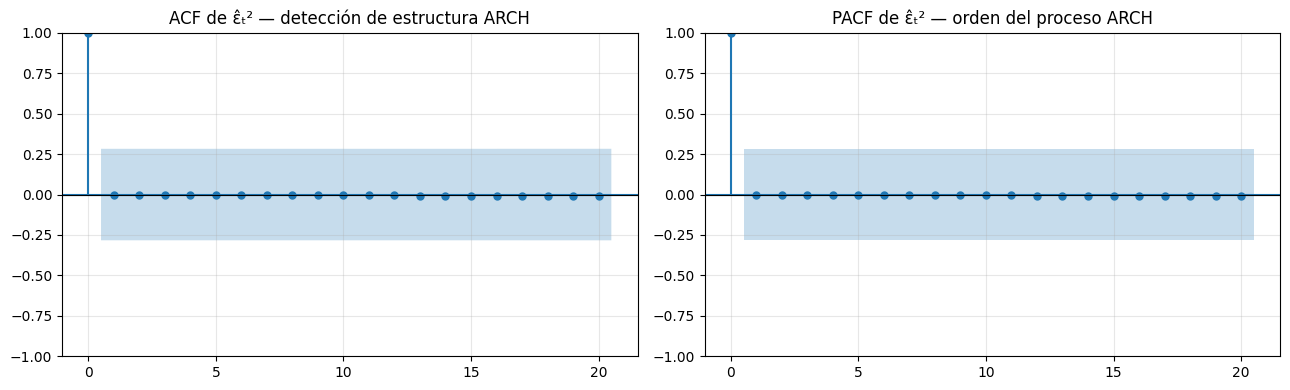

In [ ]:
# ACF y PACF de los residuos al cuadrado (identificación de orden ARCH)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax in axes:
    ax.grid(True, alpha=0.3)

plot_acf(residuos_ma1**2, lags=20, ax=axes[0],
         title='ACF de ε̂ₜ² — detección de estructura ARCH')
axes[0].axhline(y=0, color='black', linewidth=0.8)

plot_pacf(residuos_ma1**2, lags=20, ax=axes[1],
          title='PACF de ε̂ₜ² — orden del proceso ARCH',
          method='ywm')
axes[1].axhline(y=0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()


Prueba ARCH-LM — Residuos del modelo MA(1)
 Orden q      LM stat      p-valor             Conclusión
-------------------------------------------------------
       1       0.1463     0.702138     No se rechaza H0 ✓
       2       0.9918     0.609009     No se rechaza H0 ✓
       3       2.1667     0.538536     No se rechaza H0 ✓
       5       7.8885     0.162491     No se rechaza H0 ✓
      10      17.5723     0.062622     No se rechaza H0 ✓


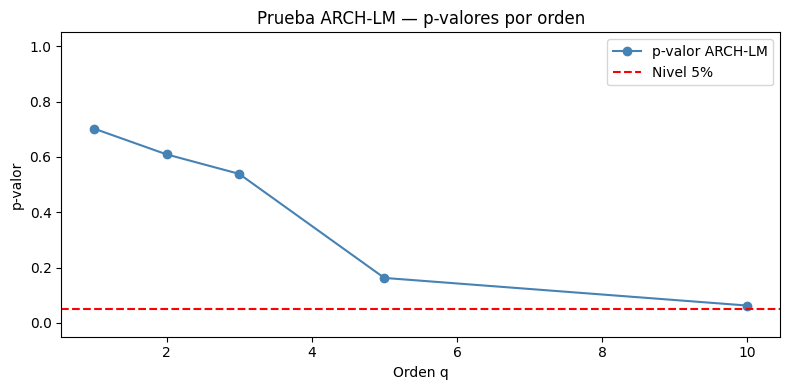

In [ ]:
# Prueba ARCH-LM (Engle, 1982)
print("Prueba ARCH-LM — Residuos del modelo MA(1)")
print("=" * 55)
print(f"{'Orden q':>8} {'LM stat':>12} {'p-valor':>12} {'Conclusión':>22}")
print("-" * 55)

arch_results = []
for q in [1, 2, 3, 5, 10]:
    lm_stat, lm_p, f_stat, f_p = het_arch(residuos_ma1, nlags=q)
    concl = "ARCH detectado ✗" if lm_p < 0.05 else "No se rechaza H0 ✓"
    arch_results.append((q, lm_stat, lm_p))
    print(f"{q:>8} {lm_stat:>12.4f} {lm_p:>12.6f} {concl:>22}")

# Visualización ARCH-LM
qs   = [r[0] for r in arch_results]
ps   = [r[2] for r in arch_results]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(qs, ps, 'o-', color='steelblue', label='p-valor ARCH-LM')
ax.axhline(0.05, color='red', linestyle='--', label='Nivel 5%')
ax.set_xlabel('Orden q')
ax.set_ylabel('p-valor')
ax.set_title('Prueba ARCH-LM — p-valores por orden')
ax.set_ylim([-0.05, 1.05])
ax.legend()
plt.tight_layout()
plt.show()


##  Modelos SARIMA


### Inspección de ACF/PACF — Identificación de órdenes estacionales

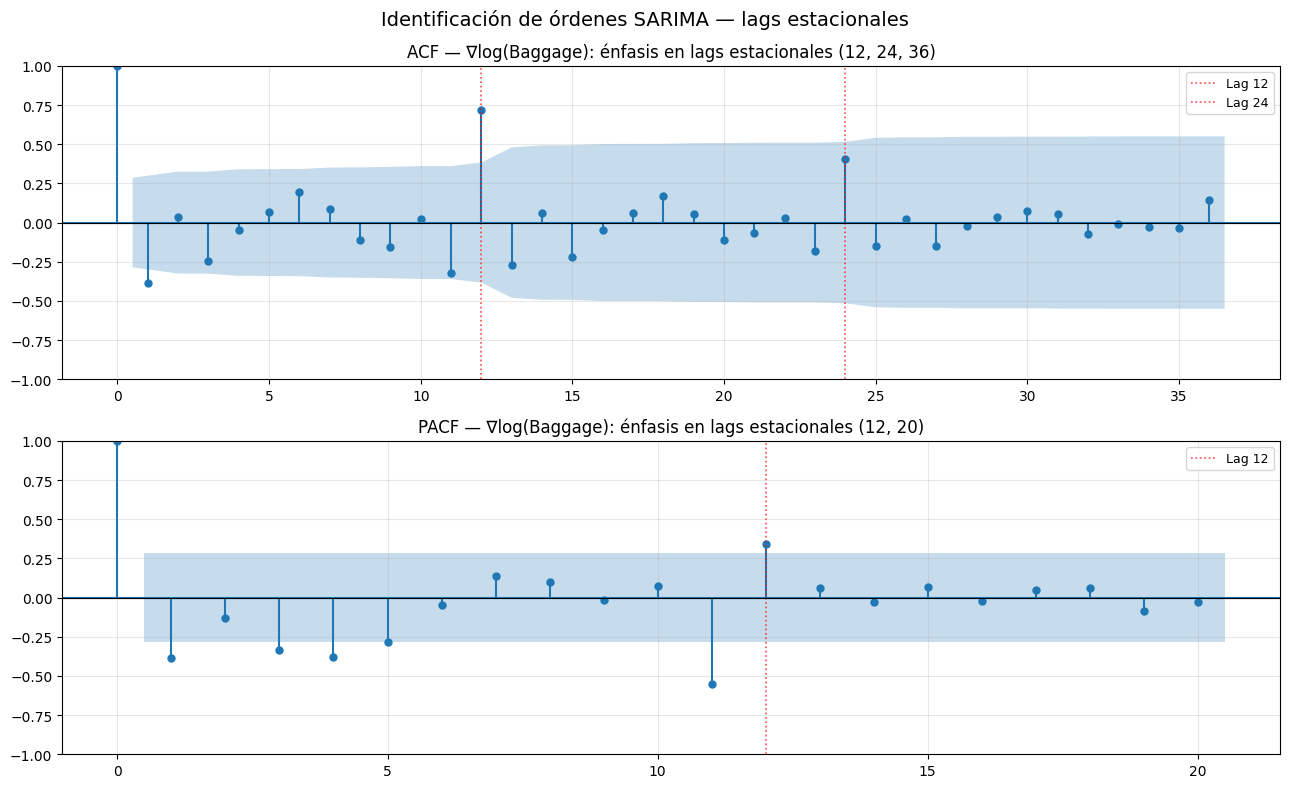

Descomposición STL de la serie original (m=12)


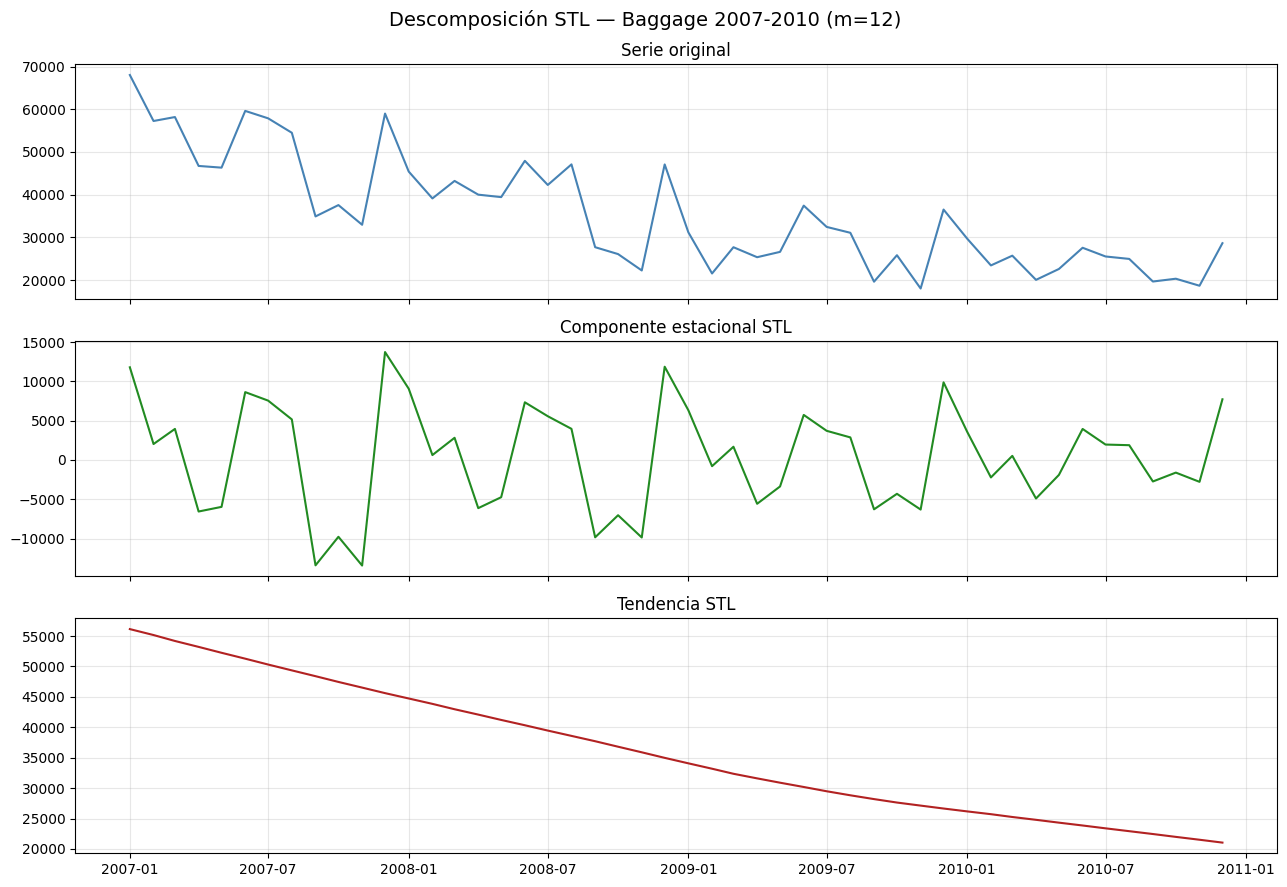

In [ ]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL

# ACF y PACF con lags hasta 36 para ver el comportamiento en lag 12 y 24
fig, axes = plt.subplots(2, 1, figsize=(13, 8))

for ax in axes:
    ax.grid(True, alpha=0.3)

plot_acf(ts_diff, lags=36, ax=axes[0],
         title='ACF — ∇log(Baggage): énfasis en lags estacionales (12, 24, 36)')
axes[0].axvline(12, color='red', linestyle=':', linewidth=1.2, alpha=0.7, label='Lag 12')
axes[0].axvline(24, color='red', linestyle=':', linewidth=1.2, alpha=0.7, label='Lag 24')
axes[0].legend(fontsize=9)
axes[0].axhline(y=0, color='black', linewidth=0.8)

plot_pacf(ts_diff, lags=20, ax=axes[1],
          title='PACF — ∇log(Baggage): énfasis en lags estacionales (12, 20)',
          method='ywm')
axes[1].axvline(12, color='red', linestyle=':', linewidth=1.2, alpha=0.7, label='Lag 12')
axes[1].legend(fontsize=9)
axes[1].axhline(y=0, color='black', linewidth=0.8)

plt.suptitle('Identificación de órdenes SARIMA — lags estacionales', fontsize=14)
plt.tight_layout()
plt.show()

# Descomposición STL para visualizar el componente estacional
print("Descomposición STL de la serie original (m=12)")
stl = STL(ts, period=12, robust=True).fit()

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
axes[0].plot(ts, color='steelblue'); axes[0].set_title('Serie original')
axes[1].plot(stl.seasonal, color='forestgreen'); axes[1].set_title('Componente estacional STL')
axes[2].plot(stl.trend, color='firebrick'); axes[2].set_title('Tendencia STL')
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.suptitle('Descomposición STL — Baggage 2007-2010 (m=12)', fontsize=14)
plt.tight_layout()
plt.show()


### Ajuste de Modelos SARIMA Candidatos

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings
warnings.filterwarnings('ignore')

m = 12  # periodo estacional anual

candidatos_sarima = [
    ("SARIMA(0,1,1)(0,1,1)_12", (0,1,1), (0,1,1,12)),
    ("SARIMA(0,1,1)(1,0,0)_12", (0,1,1), (1,0,0,12)),
    ("SARIMA(1,1,0)(0,1,1)_12", (1,1,0), (0,1,1,12)),
    ("SARIMA(0,1,1)(0,0,1)_12", (0,1,1), (0,0,1,12)),
]

resultados_sarima = {}
tabla_sarima = []

for nombre, orden, orden_s in candidatos_sarima:
    try:
        modelo = SARIMAX(ts_log, order=orden, seasonal_order=orden_s,
                         enforce_stationarity=False, enforce_invertibility=False)
        fit = modelo.fit(disp=False)
        resultados_sarima[nombre] = fit

        # Ljung-Box sobre residuos
        res = fit.resid.dropna()
        lb = acorr_ljungbox(res, lags=[10], return_df=True)
        lb_p = float(lb['lb_pvalue'].iloc[0])
        ruido_blanco = "✓" if lb_p > 0.05 else "✗"

        tabla_sarima.append({
            'Modelo': nombre,
            'AIC': round(fit.aic, 4),
            'BIC': round(fit.bic, 4),
            'LB p-val (lag 10)': round(lb_p, 4),
            'Residuos RB': ruido_blanco,
        })
        print(f"✓ {nombre}  |  AIC={fit.aic:.2f}  BIC={fit.bic:.2f}  LB_p={lb_p:.4f} {ruido_blanco}")
    except Exception as e:
        print(f"✗ {nombre}  ERROR: {e}")
        tabla_sarima.append({'Modelo': nombre, 'AIC': None, 'BIC': None, 'error': str(e)})

df_sarima = pd.DataFrame(tabla_sarima)
df_sarima_valid = df_sarima[df_sarima['AIC'].notna()].sort_values('AIC').reset_index(drop=True)

print("\n" + "=" * 70)
print("Comparación de modelos SARIMA candidatos")
print("=" * 70)
print(df_sarima_valid[['Modelo','AIC','BIC','LB p-val (lag 10)','Residuos RB']].to_string(index=False))

# Incluir MA(1) original para comparación directa
from statsmodels.tsa.arima.model import ARIMA
fit_ma1_ref = ARIMA(ts_log, order=(0,1,1)).fit()
print(f"\n  [Referencia] MA(1) — ARIMA(0,1,1): AIC={fit_ma1_ref.aic:.2f}  BIC={fit_ma1_ref.bic:.2f}")


✓ SARIMA(0,1,1)(0,1,1)_12  |  AIC=-25.29  BIC=-22.16  LB_p=1.0000 ✓
✓ SARIMA(0,1,1)(1,0,0)_12  |  AIC=-39.25  BIC=-34.59  LB_p=1.0000 ✓
✓ SARIMA(1,1,0)(0,1,1)_12  |  AIC=-25.21  BIC=-21.94  LB_p=0.9993 ✓
✓ SARIMA(0,1,1)(0,0,1)_12  |  AIC=1229.68  BIC=1234.17  LB_p=1.0000 ✓

Comparación de modelos SARIMA candidatos
                 Modelo       AIC       BIC  LB p-val (lag 10) Residuos RB
SARIMA(0,1,1)(1,0,0)_12  -39.2511  -34.5850             1.0000           ✓
SARIMA(0,1,1)(0,1,1)_12  -25.2938  -22.1603             1.0000           ✓
SARIMA(1,1,0)(0,1,1)_12  -25.2113  -21.9382             0.9993           ✓
SARIMA(0,1,1)(0,0,1)_12 1229.6772 1234.1667             1.0000           ✓

  [Referencia] MA(1) — ARIMA(0,1,1): AIC=3.11  BIC=6.81


### Diagnóstico del Mejor Modelo SARIMA

Modelo seleccionado: SARIMA(0,1,1)(1,0,0)_12
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.6255      0.158     -3.949      0.000      -0.936      -0.315
ar.S.L12       0.7975      0.079     10.107      0.000       0.643       0.952
sigma2         0.0158      0.004      3.833      0.000       0.008       0.024

AIC : -39.2511
BIC : -34.5850


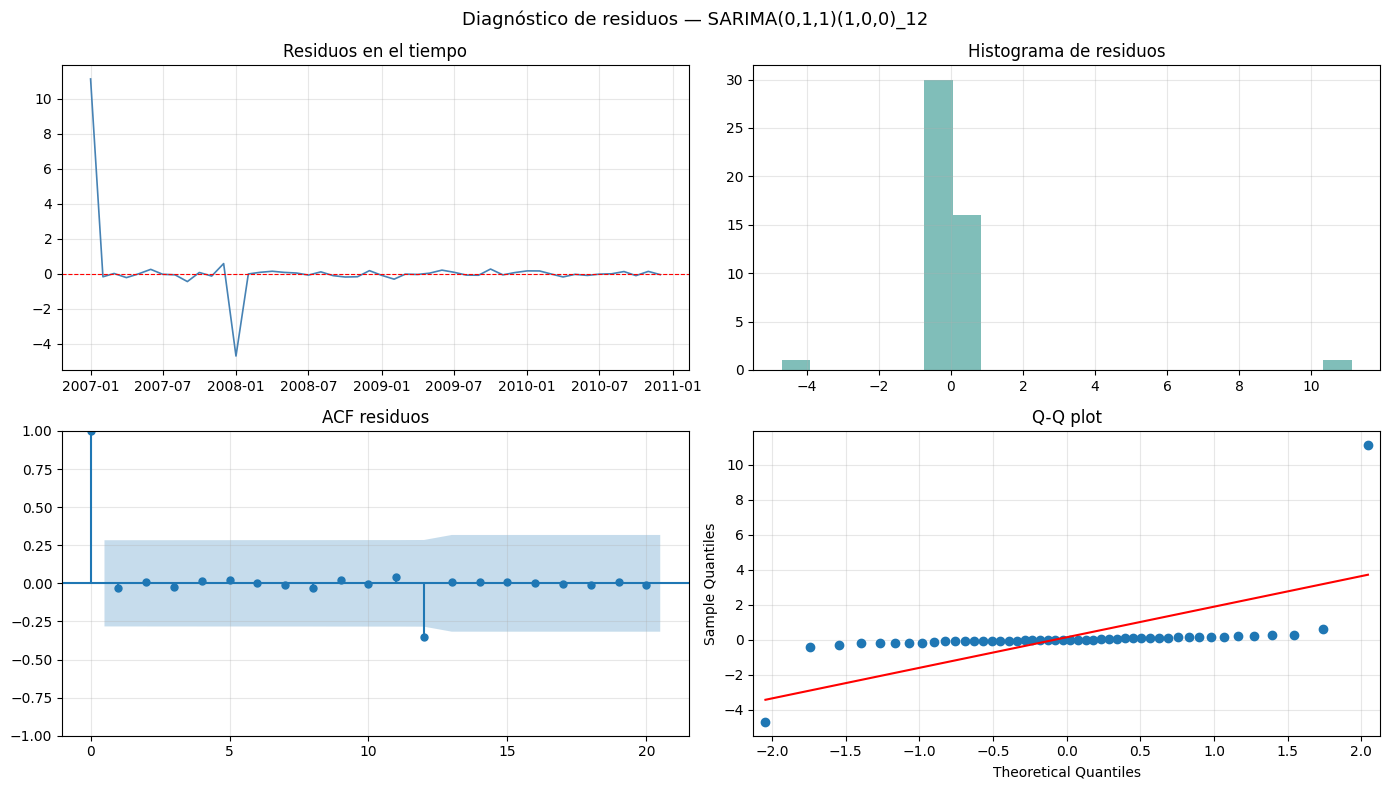


Prueba Ljung-Box sobre residuos del mejor SARIMA:
  Rezago         Q_LB      p-valor             Conclusión
-------------------------------------------------------
       5       0.1097     0.999796        No rechaza H0 ✓
      10       0.1955     1.000000        No rechaza H0 ✓
      15       8.5883     0.898040        No rechaza H0 ✓
      20       8.6085     0.987015        No rechaza H0 ✓


In [ ]:
import statsmodels.api as sm

# Seleccionar el modelo con menor AIC entre los que pasaron Ljung-Box
mejor_nombre = df_sarima_valid[df_sarima_valid['Residuos RB'] == '✓'].iloc[0]['Modelo']
fit_mejor = resultados_sarima[mejor_nombre]

print(f"Modelo seleccionado: {mejor_nombre}")
print("=" * 60)
print(fit_mejor.summary().tables[1])
print(f"\nAIC : {fit_mejor.aic:.4f}")
print(f"BIC : {fit_mejor.bic:.4f}")

# Diagnóstico completo de residuos
residuos_sarima = fit_mejor.resid.dropna()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Residuos en el tiempo
axes[0,0].plot(residuos_sarima, color='steelblue', linewidth=1.2)
axes[0,0].axhline(0, color='red', linestyle='--', linewidth=0.8)
axes[0,0].set_title('Residuos en el tiempo')
axes[0,0].grid(True, alpha=0.3)

# Histograma
axes[0,1].hist(residuos_sarima, bins=20, color='#72b7b2', alpha=0.9)
axes[0,1].set_title('Histograma de residuos')
axes[0,1].grid(True, alpha=0.3)

# ACF residuos
plot_acf(residuos_sarima, lags=20, ax=axes[1,0],
         title='ACF residuos')
axes[1,0].grid(True, alpha=0.3)

# Q-Q plot
sm.qqplot(residuos_sarima, line='s', ax=axes[1,1])
axes[1,1].set_title('Q-Q plot')
axes[1,1].grid(True, alpha=0.3)

plt.suptitle(f'Diagnóstico de residuos — {mejor_nombre}', fontsize=13)
plt.tight_layout()
plt.show()

# Ljung-Box detallado
lags_lb = [5, 10, 15, 20]
lb_sarima = acorr_ljungbox(residuos_sarima, lags=lags_lb, return_df=True)
print("\nPrueba Ljung-Box sobre residuos del mejor SARIMA:")
print(f"{'Rezago':>8} {'Q_LB':>12} {'p-valor':>12} {'Conclusión':>22}")
print("-" * 55)
for _, row in lb_sarima.iterrows():
    q = float(row['lb_stat'])
    p = float(row['lb_pvalue'])
    c = 'No rechaza H0 ✓' if p > 0.05 else 'Rechaza H0 ✗'
    print(f"{int(row.name):>8} {q:>12.4f} {p:>12.6f} {c:>22}")


## Pronóstico, Métricas y Validación Cruzada

Se evalúa el rendimiento del modelo SARIMA seleccionado fuera de muestra
y se compara directamente con el MA(1).



###Pronóstico fuera de muestra — Últimos 6 meses


Comparación de métricas — últimos 6 meses (escala original)
Métrica             MA(1)               SARIMA     Mejora
--------------------------------------------------------------
MAE               3410.50              1300.53 ↓    61.9%
RMSE              4056.87              1949.63 ↓    51.9%
MAPE %              16.29                 6.66 ↓    59.1%
sMAPE %             14.83                 7.20 ↓    51.4%


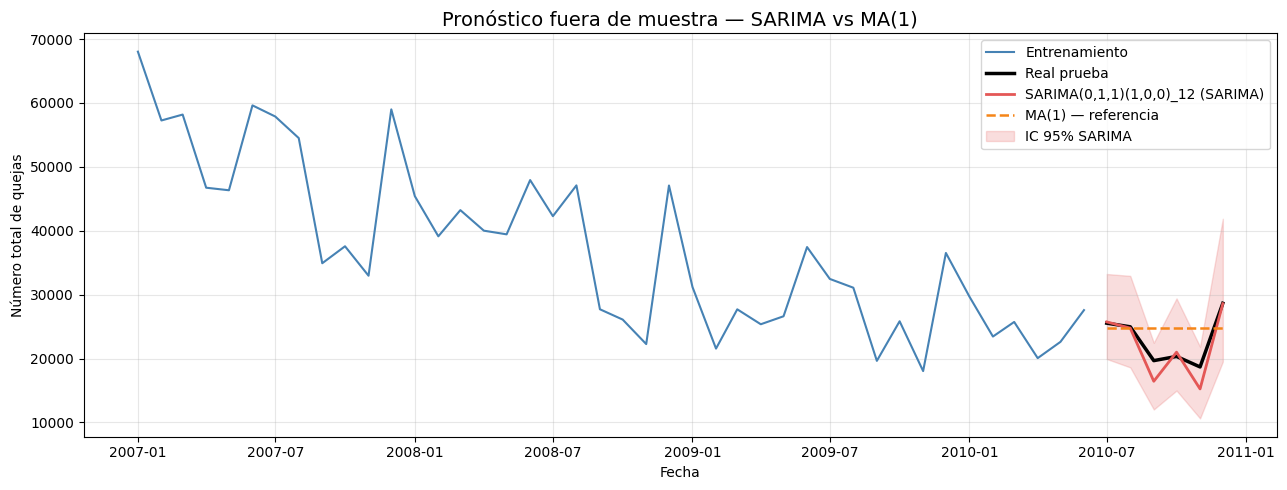

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

test_size = 6
ts_log_clean = ts_log.dropna()
train_log = ts_log_clean.iloc[:-test_size]
test_log  = ts_log_clean.iloc[-test_size:]

# Función de métricas
def calc_metrics(y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mape = np.nanmean(np.abs((y_true - y_pred) /
           np.where(np.abs(y_true) < 1e-8, np.nan, y_true))) * 100
    smape = np.nanmean(2 * np.abs(y_true - y_pred) /
            (np.abs(y_true) + np.abs(y_pred))) * 100
    return mae, rmse, mape, smape

# Pronóstico SARIMA (mejor modelo)
mejor_orden   = df_sarima_valid[df_sarima_valid['Residuos RB'] == '✓'].iloc[0]['Modelo']
mejor_entrada = [c for c in candidatos_sarima if c[0] == mejor_orden][0]
_, ord_reg, ord_s = mejor_entrada

modelo_s_train = SARIMAX(train_log, order=ord_reg, seasonal_order=ord_s,
                          enforce_stationarity=False, enforce_invertibility=False)
fit_s_train = modelo_s_train.fit(disp=False)
fc_s = fit_s_train.get_forecast(steps=test_size)
pred_s_log = fc_s.predicted_mean
ci_s       = fc_s.conf_int(alpha=0.05)
pred_s_log.index = test_log.index
ci_s.index = test_log.index

# Pronóstico MA(1) (referencia)
from statsmodels.tsa.arima.model import ARIMA
fit_ma1_tr = ARIMA(train_log, order=(0,1,1)).fit()
pred_ma1_log = fit_ma1_tr.get_forecast(steps=test_size).predicted_mean
pred_ma1_log.index = test_log.index

# Escala original
pred_s_orig   = np.exp(pred_s_log)
pred_ma1_orig = np.exp(pred_ma1_log)
test_orig     = np.exp(test_log)
train_orig    = np.exp(train_log)
ci_lower = np.exp(ci_s.iloc[:, 0])
ci_upper = np.exp(ci_s.iloc[:, 1])

# Métricas comparativas
y_true = test_orig.values
mae_s, rmse_s, mape_s, smape_s       = calc_metrics(y_true, pred_s_orig.values)
mae_m, rmse_m, mape_m, smape_m       = calc_metrics(y_true, pred_ma1_orig.values)

print("Comparación de métricas — últimos 6 meses (escala original)")
print("=" * 62)
print(f"{'Métrica':<12} {'MA(1)':>12} {mejor_orden.split('(')[0].strip():>20} {'Mejora':>10}")
print("-" * 62)
for metrica, val_ma, val_s in [
    ('MAE',     mae_m,   mae_s),
    ('RMSE',    rmse_m,  rmse_s),
    ('MAPE %',  mape_m,  mape_s),
    ('sMAPE %', smape_m, smape_s),
]:
    mejora = (val_ma - val_s) / val_ma * 100
    signo = "↓" if mejora > 0 else "↑"
    print(f"{metrica:<12} {val_ma:>12.2f} {val_s:>20.2f} {signo}{abs(mejora):>8.1f}%")

# Gráfica comparativa
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train_orig, color='steelblue', label='Entrenamiento', linewidth=1.5)
ax.plot(test_orig, color='black', linewidth=2.5, label='Real prueba')
ax.plot(pred_s_orig, color='#e45756', linestyle='-', linewidth=2,
        label=f'{mejor_orden} (SARIMA)')
ax.plot(pred_ma1_orig, color='#f58518', linestyle='--', linewidth=1.8,
        label='MA(1) — referencia')
ax.fill_between(pred_s_orig.index, ci_lower, ci_upper,
                alpha=0.2, color='#e45756', label='IC 95% SARIMA')
ax.set_title(f'Pronóstico fuera de muestra — SARIMA vs MA(1)', fontsize=14)
ax.set_xlabel('Fecha')
ax.set_ylabel('Número total de quejas')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Tabla mensual detallada
print("Comparación mensual — Real vs MA(1) vs SARIMA")
print("=" * 72)
print(f"{'Mes':>12} {'Real':>9} {'MA(1)':>10} {'Err MA%':>9} {'SARIMA':>10} {'Err SARIMA%':>12}")
print("-" * 72)
for fecha, real, p_ma, p_s in zip(test_orig.index, y_true,
                                   pred_ma1_orig.values, pred_s_orig.values):
    err_ma = abs(real - p_ma) / real * 100
    err_s  = abs(real - p_s)  / real * 100
    mejor_mes = "✓" if err_s < err_ma else " "
    print(f"{str(fecha.date()):>12} {real:>9.0f} {p_ma:>10.0f} {err_ma:>8.1f}% "
          f"{p_s:>10.0f} {err_s:>10.1f}% {mejor_mes}")


Comparación mensual — Real vs MA(1) vs SARIMA
         Mes      Real      MA(1)   Err MA%     SARIMA  Err SARIMA%
------------------------------------------------------------------------
  2010-07-01     25535      24785      2.9%      25733        0.8% ✓
  2010-08-01     24965      24785      0.7%      24759        0.8%  
  2010-09-01     19671      24785     26.0%      16442       16.4% ✓
  2010-10-01     20328      24785     21.9%      20995        3.3% ✓
  2010-11-01     18684      24785     32.7%      15242       18.4% ✓
  2010-12-01     28646      24785     13.5%      28585        0.2% ✓


###  Validación Cruzada Temporal


Validación cruzada temporal — MA(1), one-step ahead
 fold test_fecha         MAE        RMSE    MAPE_%
    1 2010-01-01 2718.359777 2718.359777  9.155193
    2 2010-02-01 4357.027285 4357.027285 18.586414
    3 2010-03-01  636.940424  636.940424  2.476055
    4 2010-04-01 6101.116208 6101.116208 30.412822
    5 2010-05-01 1453.402008 1453.402008  6.428138
    6 2010-06-01 4000.972950 4000.972950 14.509421
    7 2010-07-01  749.673235  749.673235  2.935865
    8 2010-08-01   49.529592   49.529592  0.198396
    9 2010-09-01 5328.279779 5328.279779 27.086980
   10 2010-10-01 2891.431655 2891.431655 14.223887
   11 2010-11-01 3566.523771 3566.523771 19.088652
   12 2010-12-01 7656.151891 7656.151891 26.726775

Promedios:
  MAE    promedio : 3292.45
  RMSE   promedio : 3292.45
  MAPE%  promedio : 14.32%


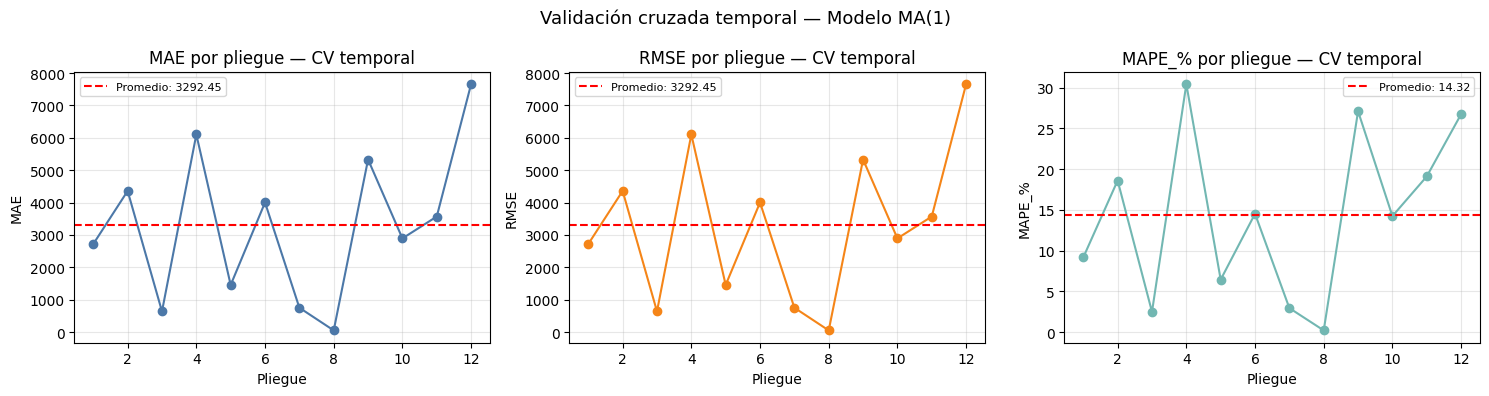

In [ ]:
# Validación cruzada temporal — expanding window
# Parámetros
horizon       = 1        # one-step ahead
initial_train = len(ts_log_clean) - 12  # empezamos con todos excepto los últimos 12
ts_cv = ts_log_clean.copy()

cv_records = []
fold = 0

for start in range(initial_train, len(ts_cv) - horizon + 1):
    fold += 1
    train_cv = ts_cv.iloc[:start]
    test_cv  = ts_cv.iloc[start:start + horizon]

    try:
        res_cv = ARIMA(train_cv, order=(0, 1, 1)).fit()
        pred_cv = res_cv.get_forecast(steps=horizon).predicted_mean
        pred_cv.index = test_cv.index

        # Métricas en escala original
        y_t = np.exp(test_cv.values)
        y_p = np.exp(pred_cv.values)

        mae_cv  = mean_absolute_error(y_t, y_p)
        rmse_cv = mean_squared_error(y_t, y_p) ** 0.5
        mape_cv = np.nanmean(np.abs((y_t - y_p) / np.where(np.abs(y_t) < 1e-8, np.nan, y_t))) * 100

        cv_records.append({
            'fold': fold,
            'train_fin': train_cv.index[-1],
            'test_fecha': test_cv.index[0],
            'MAE': mae_cv,
            'RMSE': rmse_cv,
            'MAPE_%': mape_cv,
        })
    except Exception as e:
        cv_records.append({'fold': fold, 'error': str(e)})

cv_df = pd.DataFrame([r for r in cv_records if 'error' not in r])

print("Validación cruzada temporal — MA(1), one-step ahead")
print("=" * 55)
print(cv_df[['fold', 'test_fecha', 'MAE', 'RMSE', 'MAPE_%']].to_string(index=False))

print("\nPromedios:")
print(f"  MAE    promedio : {cv_df['MAE'].mean():.2f}")
print(f"  RMSE   promedio : {cv_df['RMSE'].mean():.2f}")
print(f"  MAPE%  promedio : {cv_df['MAPE_%'].mean():.2f}%")

# Gráfica de métricas por pliegue
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, color in zip(axes, ['MAE', 'RMSE', 'MAPE_%'], ['#4c78a8', '#f58518', '#72b7b2']):
    ax.plot(cv_df['fold'], cv_df[col], 'o-', color=color)
    ax.axhline(cv_df[col].mean(), color='red', linestyle='--',
               label=f'Promedio: {cv_df[col].mean():.2f}')
    ax.set_xlabel('Pliegue')
    ax.set_ylabel(col)
    ax.set_title(f'{col} por pliegue — CV temporal')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Validación cruzada temporal — Modelo MA(1)', fontsize=13)
plt.tight_layout()
plt.show()


In [ ]:
# Validación cruzada temporal — SARIMA (expanding window)
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Recuperar órdenes del mejor modelo SARIMA
mejor_orden_sarima   = df_sarima_valid[df_sarima_valid['Residuos RB'] == '✓'].iloc[0]['Modelo']
mejor_entrada_sarima = [c for c in candidatos_sarima if c[0] == mejor_orden_sarima][0]
_, ord_reg_s, ord_s_s = mejor_entrada_sarima

horizon_s      = 1
initial_train_s = len(ts_log_clean) - 12
ts_cv_s = ts_log_clean.copy()

cv_sarima_records = []
fold_s = 0

for start in range(initial_train_s, len(ts_cv_s) - horizon_s + 1):
    fold_s += 1
    train_cv_s = ts_cv_s.iloc[:start]
    test_cv_s  = ts_cv_s.iloc[start:start + horizon_s]

    try:
        res_s = SARIMAX(train_cv_s, order=ord_reg_s, seasonal_order=ord_s_s,
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        pred_s_cv = res_s.get_forecast(steps=horizon_s).predicted_mean
        pred_s_cv.index = test_cv_s.index

        y_t = np.exp(test_cv_s.values)
        y_p = np.exp(pred_s_cv.values)

        mae_s_cv  = mean_absolute_error(y_t, y_p)
        rmse_s_cv = mean_squared_error(y_t, y_p) ** 0.5
        mape_s_cv = np.nanmean(np.abs((y_t - y_p) / np.where(np.abs(y_t) < 1e-8, np.nan, y_t))) * 100

        cv_sarima_records.append({
            'fold': fold_s,
            'test_fecha': test_cv_s.index[0],
            'MAE': mae_s_cv, 'RMSE': rmse_s_cv, 'MAPE_%': mape_s_cv,
        })
    except Exception as e:
        cv_sarima_records.append({'fold': fold_s, 'error': str(e)})

cv_sarima_df = pd.DataFrame([r for r in cv_sarima_records if 'error' not in r])

print(f"Validación cruzada temporal — {mejor_orden_sarima}, one-step ahead")
print("=" * 55)
print(cv_sarima_df[['fold', 'test_fecha', 'MAE', 'RMSE', 'MAPE_%']].to_string(index=False))
print(f"\nPromedios SARIMA:")
print(f"  MAE    promedio : {cv_sarima_df['MAE'].mean():.2f}")
print(f"  RMSE   promedio : {cv_sarima_df['RMSE'].mean():.2f}")
print(f"  MAPE%  promedio : {cv_sarima_df['MAPE_%'].mean():.2f}%")


Validación cruzada temporal — SARIMA(0,1,1)(1,0,0)_12, one-step ahead
 fold test_fecha         MAE        RMSE    MAPE_%
    1 2010-01-01 4712.791617 4712.791617 15.872261
    2 2010-02-01 4357.507874 4357.507874 18.588465
    3 2010-03-01 1507.975615 1507.975615  5.862135
    4 2010-04-01 4239.591750 4239.591750 21.133502
    5 2010-05-01  516.319286  516.319286  2.283588
    6 2010-06-01 3658.703180 3658.703180 13.268189
    7 2010-07-01  197.826469  197.826469  0.774727
    8 2010-08-01  305.417172  305.417172  1.223381
    9 2010-09-01 3188.282697 3188.282697 16.208036
   10 2010-10-01 2469.826599 2469.826599 12.149875
   11 2010-11-01 2652.035884 2652.035884 14.194155
   12 2010-12-01 1734.374206 1734.374206  6.054507

Promedios SARIMA:
  MAE    promedio : 2461.72
  RMSE   promedio : 2461.72
  MAPE%  promedio : 10.63%


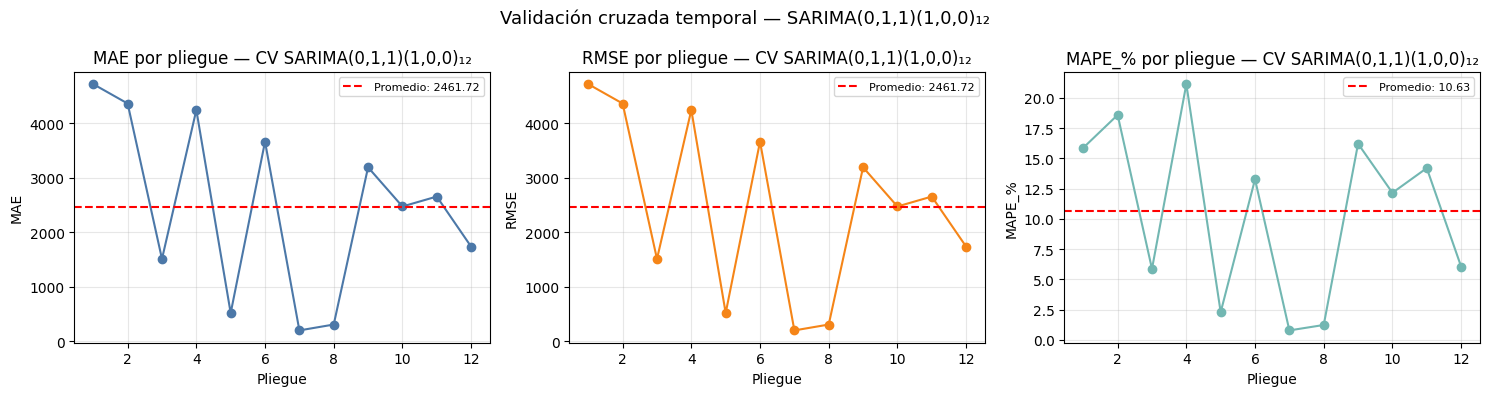

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, color in zip(axes, ['MAE', 'RMSE', 'MAPE_%'],
                           ['#4c78a8', '#f58518', '#72b7b2']):
    ax.plot(cv_sarima_df['fold'], cv_sarima_df[col], 'o-', color=color)
    ax.axhline(cv_sarima_df[col].mean(), color='red', linestyle='--',
               label=f'Promedio: {cv_sarima_df[col].mean():.2f}')
    ax.set_xlabel('Pliegue')
    ax.set_ylabel(col)
    ax.set_title(f'{col} por pliegue — CV SARIMA(0,1,1)(1,0,0)₁₂')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Validación cruzada temporal — SARIMA(0,1,1)(1,0,0)₁₂', fontsize=13)
plt.tight_layout()
plt.show()

### Conclusión

**Modelo definitivo: SARIMA(0,1,1)(1,0,0)₁₂**